# Black-Litterman walkthrough

This notebook builds intuition for the model on a small, fully specified example, then runs it on live market data.

1. The equilibrium prior: what returns would make today's market portfolio optimal?
2. Views: how one opinion moves the posterior, and why only the assets it touches get re-weighted
3. Confidence: what Idzorek's 0-100% confidence actually means
4. Real data: Ledoit-Wolf covariance, market caps, and an implied risk aversion

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from blacklitterman import (
    BlackLitterman,
    efficient_frontier,
    ledoit_wolf,
    max_sharpe,
    portfolio_performance,
    returns_from_prices,
)
from blacklitterman.plotting import PALETTE, plot_efficient_frontier, plot_returns, plot_weights

pd.options.display.float_format = "{:.2%}".format
%config InlineBackend.figure_format = "retina"

## 1. The equilibrium prior

Start with five asset classes, their volatilities and correlations, and their share of world market cap. If the market portfolio is mean-variance optimal for an investor with risk aversion $\delta$, the expected returns must be

$$\Pi = r_f + \delta\,\Sigma\,w_{mkt}$$

This is *reverse optimisation*. Instead of estimating noisy historical means, we back them out of prices.

In [2]:
assets = ["US", "EU", "JP", "EM", "BOND"]
vols = np.array([0.16, 0.18, 0.17, 0.24, 0.06])
corr = np.array(
    [
        [1.00, 0.75, 0.55, 0.65, 0.10],
        [0.75, 1.00, 0.55, 0.65, 0.15],
        [0.55, 0.55, 1.00, 0.55, 0.10],
        [0.65, 0.65, 0.55, 1.00, 0.05],
        [0.10, 0.15, 0.10, 0.05, 1.00],
    ]
)
cov = pd.DataFrame(np.outer(vols, vols) * corr, index=assets, columns=assets)
caps = pd.Series([45, 15, 6, 10, 24], index=assets, dtype=float)

bl = BlackLitterman(cov, market_caps=caps, risk_aversion=2.5, tau=0.05, risk_free_rate=0.03)
bl.summary()

,market_weight,prior,posterior,view_impact,bl_weight
US,45.00%,7.60%,7.60%,0.00%,42.86%
EU,15.00%,7.70%,7.70%,0.00%,14.29%
JP,6.00%,6.37%,6.37%,0.00%,5.71%
EM,10.00%,8.68%,8.68%,0.00%,9.52%
BOND,24.00%,3.42%,3.42%,0.00%,22.86%


With no views, the posterior equals the prior. The unconstrained optimal weights are the market weights scaled by $1/(1+\tau)$: the investor holds the market, slightly de-levered for estimation risk (He & Litterman, 1999).

## 2. Adding views

Two opinions:
- **Absolute:** emerging markets will return 12%. The prior implies about 9%.
- **Relative:** Europe will outperform the US by 2%. The prior implies they return about the same.

In [3]:
bl.add_absolute_view("EM", 0.12, confidence=0.5)
bl.add_relative_view("EU", "US", 0.02, confidence=0.5)
bl.summary()

,market_weight,prior,posterior,view_impact,bl_weight
US,45.00%,7.60%,8.03%,0.43%,18.94%
EU,15.00%,7.70%,9.12%,1.42%,38.20%
JP,6.00%,6.37%,7.09%,0.72%,5.71%
EM,10.00%,8.68%,10.44%,1.76%,21.05%
BOND,24.00%,3.42%,3.48%,0.06%,22.86%


In [4]:
bl.view_summary()

,q,prior_implied,posterior_implied,confidence,omega
view,,,,,
EM = 12.0%,12.00%,8.68%,10.44%,50.00%,0.29%
EU − US = +2.0%,2.00%,0.10%,1.09%,50.00%,0.07%


Correlated assets move too: JP's expected return changes even though no view mentions it. The **weights** behave differently. JP and BOND keep exactly their (scaled) market weight. Black-Litterman tilts the portfolio only along the view portfolios, which is why its allocations stay intuitive where naive mean-variance optimisation produces corner solutions.

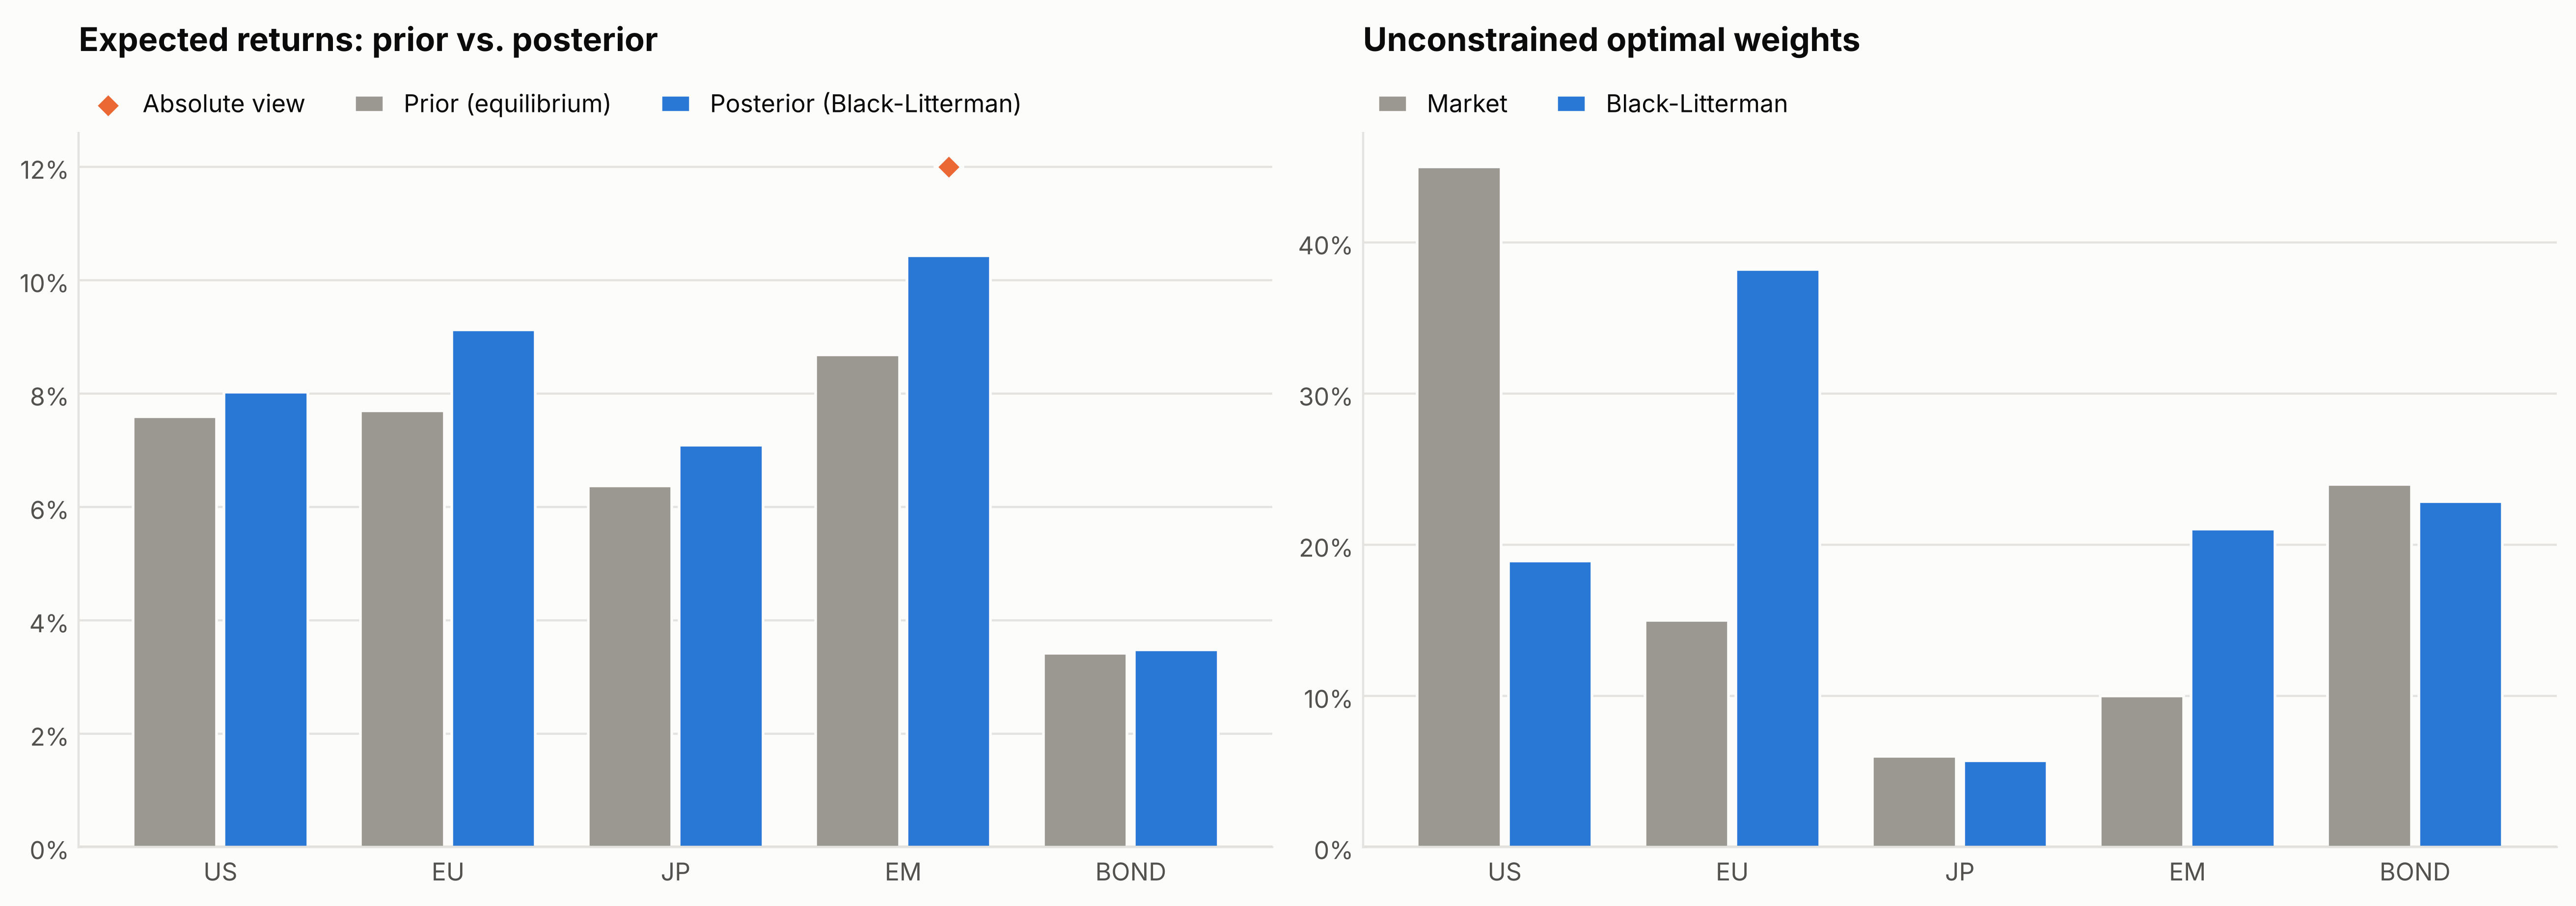

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
plot_returns(bl, ax=axes[0])
plot_weights(
    {"Market": bl.market_weights, "Black-Litterman": bl.implied_weights()},
    ax=axes[1],
    title="Unconstrained optimal weights",
);

## 3. What does "confidence" mean?

The raw model needs a view variance $\Omega$, which nobody has intuition for. Idzorek (2005) proposed a 0-100% confidence instead. This package uses Walters' closed form

$$\Omega_k = \frac{1-c_k}{c_k}\; p_k\,\tau\Sigma\,p_k^\top$$

This gives the property Idzorek intended: **at confidence $c$, the posterior moves exactly a fraction $c$ of the way from the prior to where a 100%-certain view would put it.** At $c = 1$ the view holds exactly. The model uses the $\Omega$-free update form, so $\Omega = 0$ causes no numerical trouble.

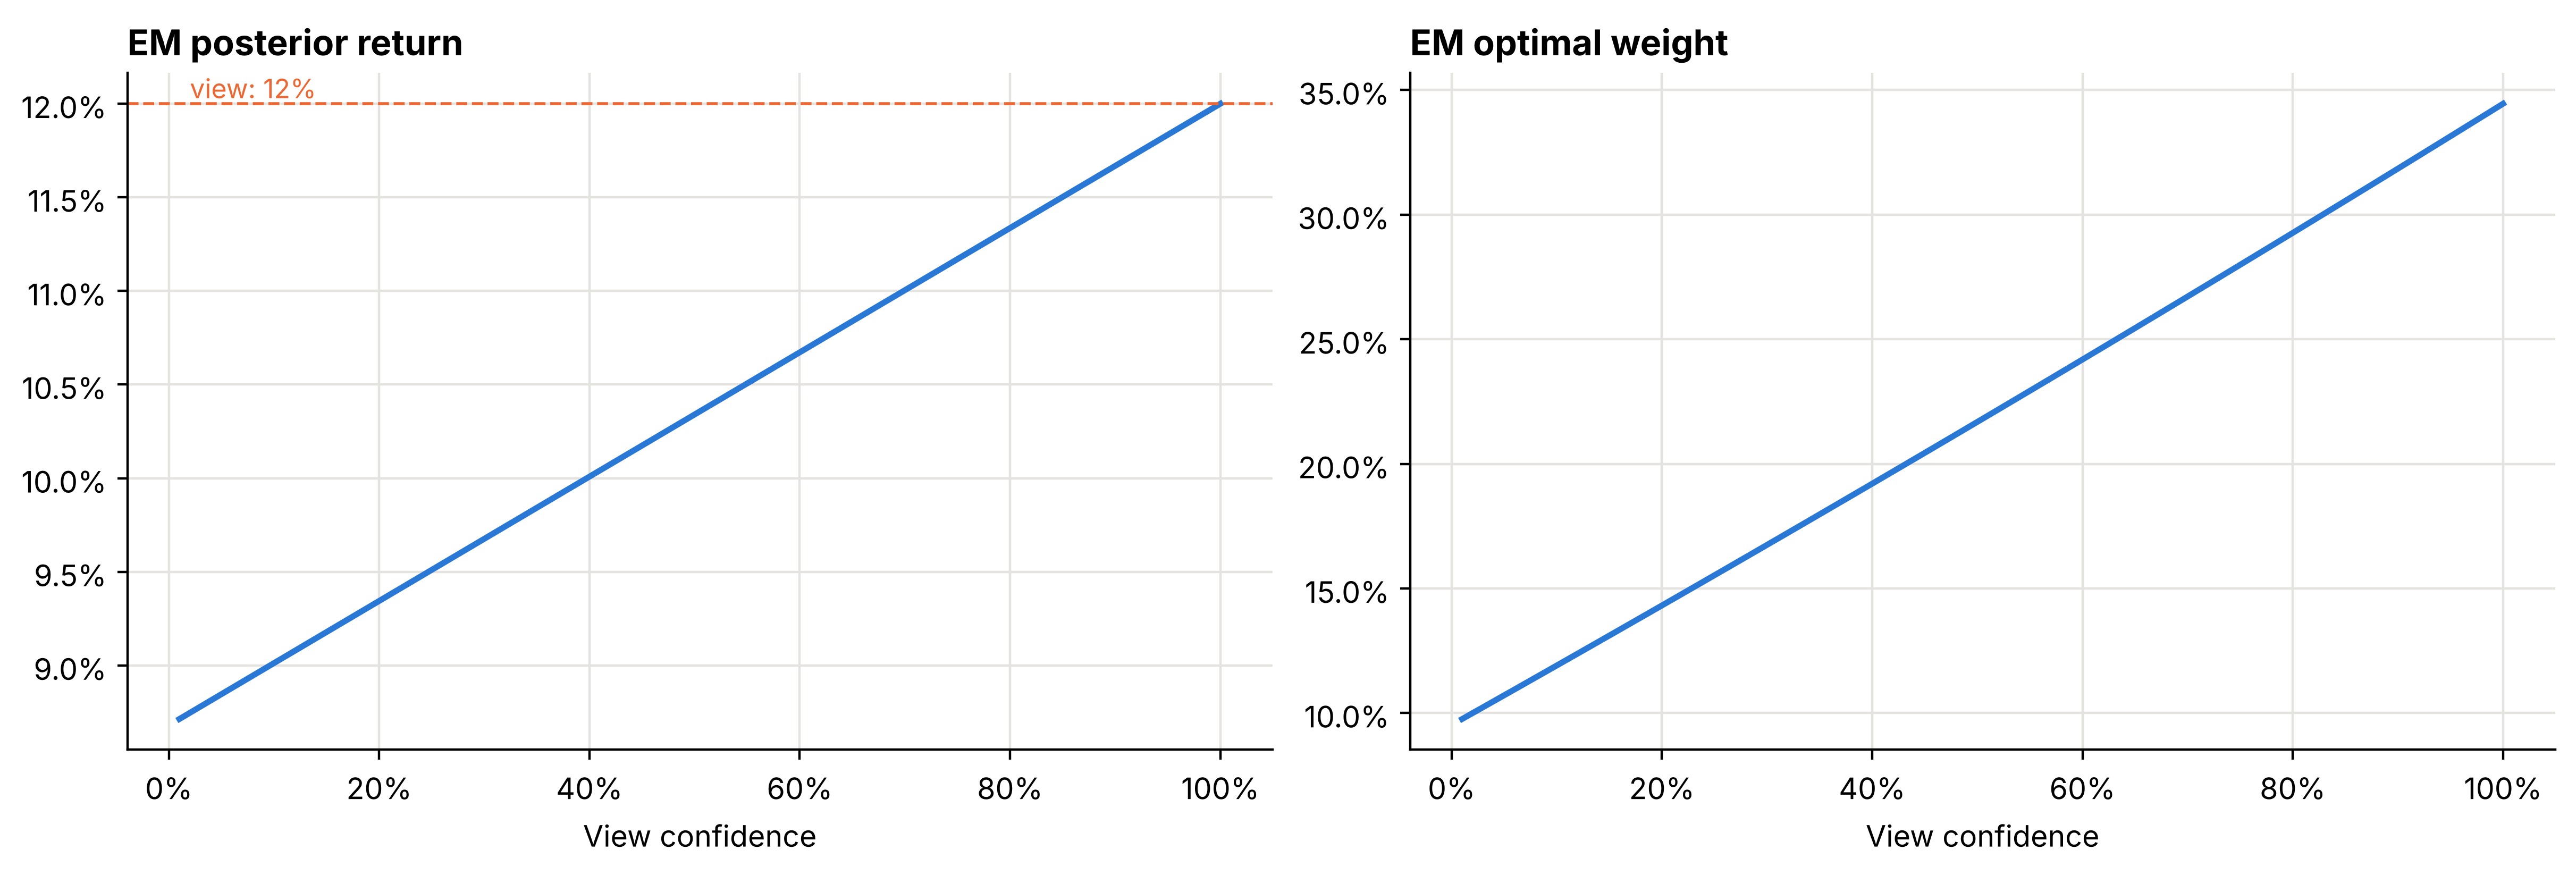

In [6]:
conf = np.linspace(0.01, 1, 40)
em_ret, em_w = [], []
for c in conf:
    m = BlackLitterman(cov, market_caps=caps, risk_aversion=2.5, tau=0.05, risk_free_rate=0.03)
    m.add_absolute_view("EM", 0.12, confidence=c)
    em_ret.append(m.posterior_returns()["EM"])
    em_w.append(m.implied_weights()["EM"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, y, ttl in [(axes[0], em_ret, "EM posterior return"), (axes[1], em_w, "EM optimal weight")]:
    ax.plot(conf, y, color=PALETTE["blue"], lw=2)
    ax.set_title(ttl, loc="left", fontweight="bold")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=1))
    ax.set_xlabel("View confidence")
    ax.grid(color=PALETTE["grid"])
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].axhline(0.12, color=PALETTE["orange"], ls="--", lw=1)
axes[0].annotate("view: 12%", (0.02, 0.1203), color=PALETTE["orange"], fontsize=9)
fig.savefig("../docs/images/confidence.png", dpi=160, facecolor="white")

Both lines are straight: confidence maps linearly onto how far the view is allowed to move the portfolio.

## 4. Live data

Eight US large caps. The covariance comes from five years of daily returns with Ledoit-Wolf shrinkage. Weights come from current market caps. $\delta$ is implied by SPY's excess return and variance over the same window.

*(Requires network access and `pip install -e ".[data]"`. The views are illustrative, not investment advice.)*

In [7]:
from blacklitterman.data import fetch_market_caps, fetch_prices, market_implied_risk_aversion

tickers = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL", "JPM", "XOM", "JNJ"]
rf = 0.04
prices = fetch_prices([*tickers, "SPY"], period="5y")
cov_live = ledoit_wolf(returns_from_prices(prices[tickers]))
caps_live = fetch_market_caps(tickers)
delta = market_implied_risk_aversion(prices["SPY"], rf)
print(f"shrinkage={cov_live.attrs['shrinkage']:.3f}  delta={delta:.2f}")

live = BlackLitterman(cov_live, market_caps=caps_live, risk_aversion=delta, tau=0.05, risk_free_rate=rf)
live.add_absolute_view("JPM", 0.14, confidence=0.6)
live.add_relative_view("XOM", "NVDA", 0.05, confidence=0.4)
live.add_view({"JNJ": 0.5, "GOOGL": 0.5}, 0.12, confidence=0.3)
live.summary()

shrinkage=0.013  delta=2.57


,market_weight,prior,posterior,view_impact,bl_weight
AAPL,24.30%,17.91%,16.79%,-1.12%,23.14%
MSFT,17.91%,18.48%,16.35%,-2.13%,17.05%
NVDA,17.29%,30.95%,22.66%,-8.29%,2.64%
AMZN,13.73%,22.51%,20.25%,-2.26%,13.08%
GOOGL,16.47%,20.14%,18.14%,-2.00%,16.58%
JPM,4.08%,11.38%,12.58%,1.21%,18.20%
XOM,3.11%,6.32%,9.31%,2.99%,16.79%
JNJ,3.11%,4.46%,5.46%,1.00%,3.86%


In [8]:
mu, pc = live.posterior_returns(), live.posterior_cov()
w = max_sharpe(mu, pc, risk_free_rate=rf, bounds=(0, 0.35))
perf = pd.DataFrame(
    {
        name: portfolio_performance(x, mu, pc, rf)
        for name, x in {"Market": live.market_weights, "BL max-Sharpe": w}.items()
    }
)
perf.style.format("{:.3f}")

,Market,BL max-Sharpe
expected_return,0.177,0.153
volatility,0.255,0.198
sharpe_ratio,0.536,0.568
effective_n,5.862,6.500


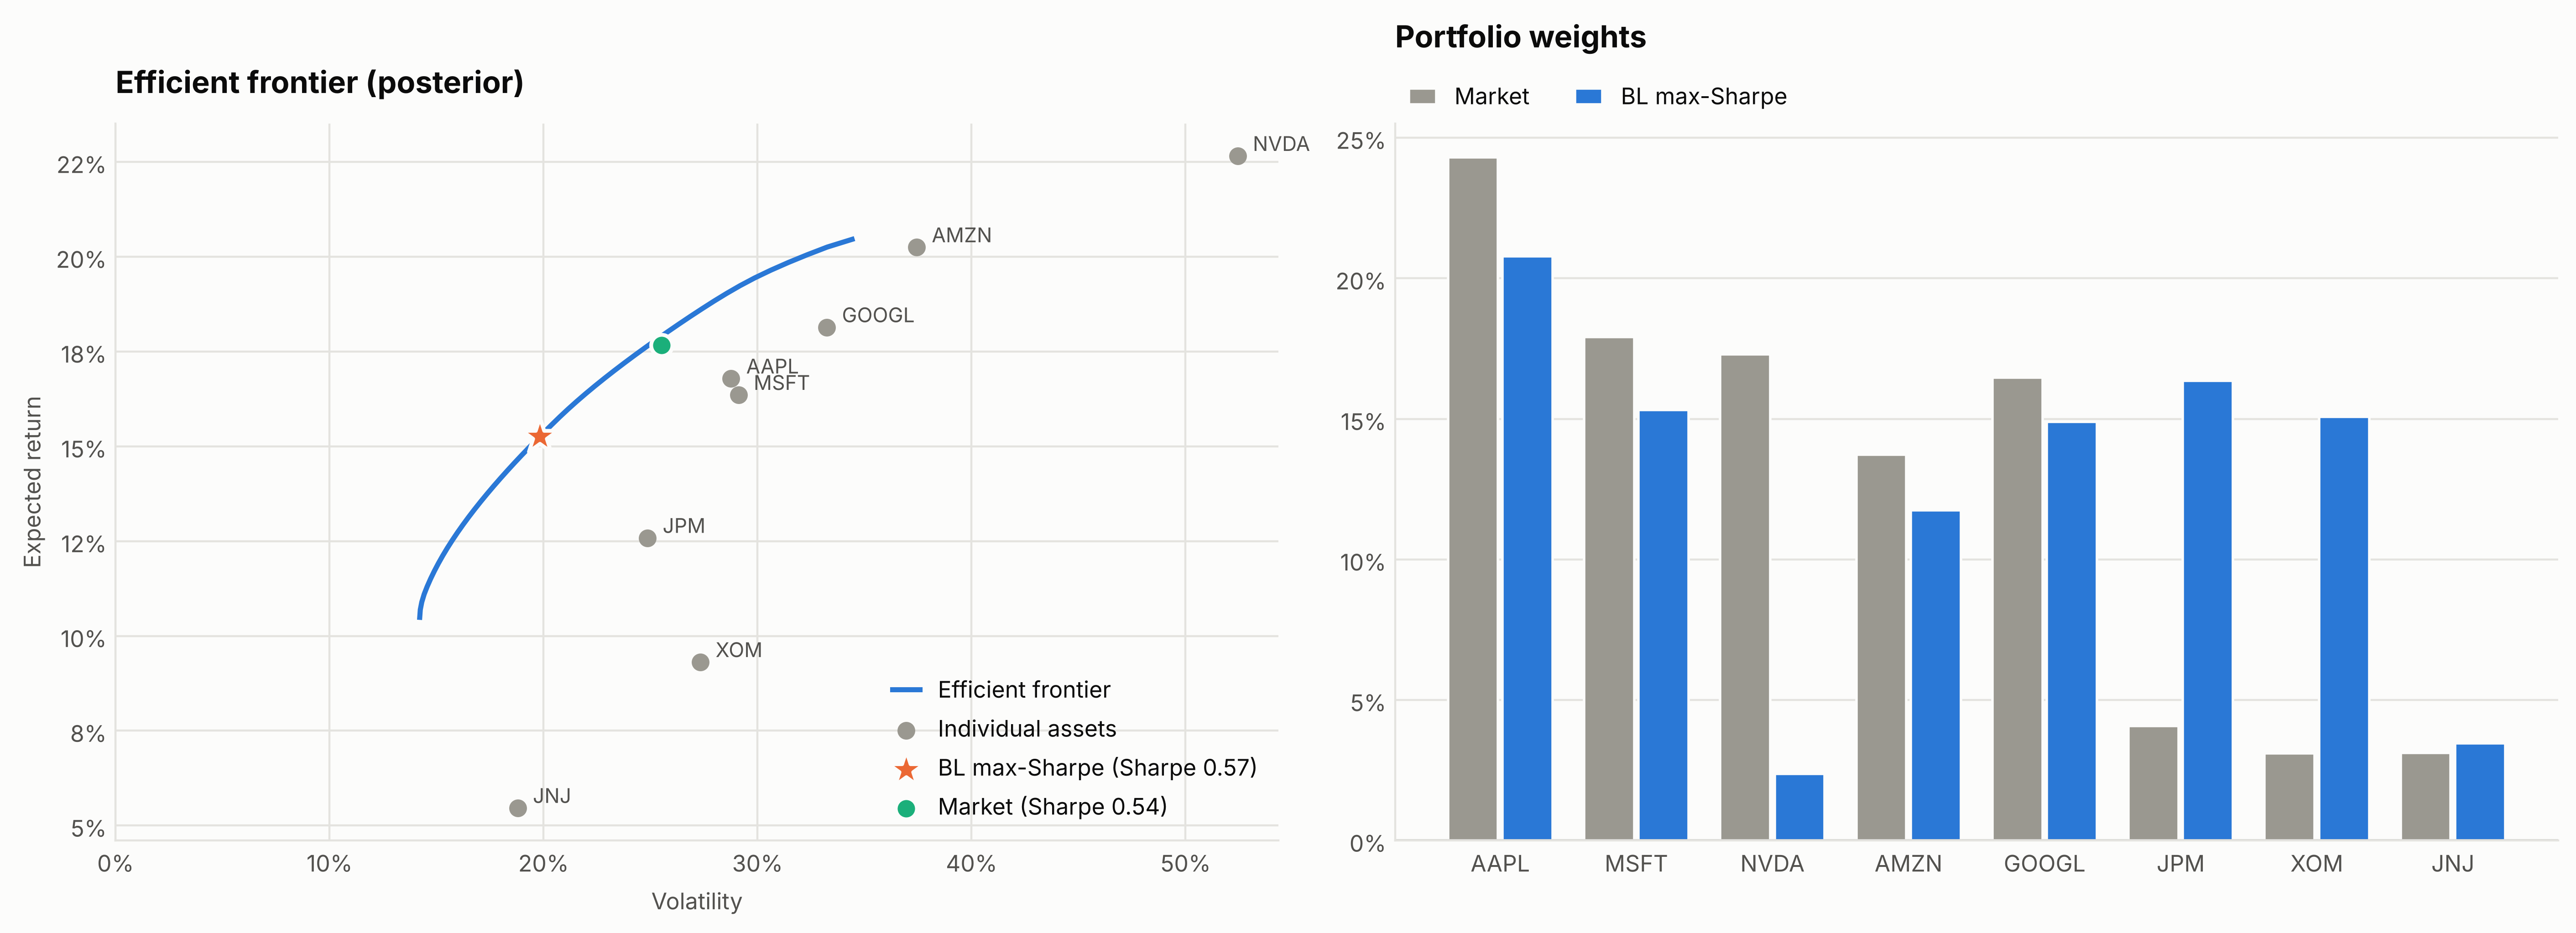

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
plot_efficient_frontier(
    efficient_frontier(mu, pc, 50, bounds=(0, 0.35)),
    mu,
    pc,
    {"BL max-Sharpe": w, "Market": live.market_weights},
    rf,
    ax=axes[0],
)
plot_weights({"Market": live.market_weights, "BL max-Sharpe": w}, ax=axes[1]);

## Takeaways

- The equilibrium prior gives sensible, diversified expected returns without estimating means from history.
- Views change the portfolio only where you have an opinion, by an amount set by an interpretable confidence.
- Posterior returns feed any optimiser. The constrained max-Sharpe here is a convex QP, using the Cornuejols-Tütüncü transform.